# 🔬 Notebook 1 — Teoría
# Lenguajes de Programación para Computación Cuántica

**Geronimo Martinez Núñez · Angel Nicolás Cuervo**  
Trabajo de Curso — Lenguajes de Programación

---

> *"El programador de computadores es un creador de universos de los cuales él solo es el legislador..."*  
> — J. Weizenbaum, *Computer Power and Human Reason*

---

## Índice

1. [¿Qué es programar un computador cuántico?](#sec1)
2. [Modelos de cómputo cuántico](#sec2)
3. [La arquitectura QRAM](#sec3)
4. [Ensamblador cuántico: registros, puertas y medición](#sec4)
5. [Taxonomía de lenguajes cuánticos de alto nivel](#sec5)
6. [El modelo híbrido clásico-cuántico](#sec6)
7. [Emuladores cuánticos](#sec7)
8. [Referencias y lectura adicional](#sec8)

---
<a id='sec1'></a>
## 1. ¿Qué es programar un computador cuántico?

### 1.1 Programación clásica vs. cuántica

En la programación clásica conocemos bien el siguiente principio:

$$\boxed{\textbf{DATOS} + \textbf{CONTROL} = \textbf{PROGRAMACIÓN}}$$

Los **datos** son secuencias de bits: 0s y 1s.  
El **control** son estructuras como condicionales (`if/else`), bucles (`while`, `for`), y saltos.

En computación cuántica, este esquema se traslada directamente:

$$\boxed{\textbf{DATOS CUÁNTICOS} + \textbf{CONTROL} = \textbf{PROGRAMACIÓN CUÁNTICA}}$$

Pero los **datos cuánticos** son qubits —unidades de información que pueden estar en **superposición** de 0 y 1 simultáneamente— y las operaciones son **transformaciones unitarias** y **mediciones**.

### 1.2 El qubit como dato fundamental

Un qubit se describe matemáticamente como un vector en $\mathbb{C}^2$:

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \quad \alpha, \beta \in \mathbb{C}, \quad |\alpha|^2 + |\beta|^2 = 1$$

Donde $|0\rangle = \begin{pmatrix}1\\0\end{pmatrix}$ y $|1\rangle = \begin{pmatrix}0\\1\end{pmatrix}$ son los estados base.

### 1.3 Dos tipos de operaciones cuánticas

| Operación | Tipo | Característica |
|-----------|------|----------------|
| **Puerta cuántica** | Transformación unitaria $U$ | Reversible, preserva la norma |
| **Medición** | Proyección | Destructiva: colapsa el estado |

Una transformación $U$ es unitaria si $U U^\dagger = I$, lo cual garantiza que la evolución sea reversible (y por tanto físicamente realizable).

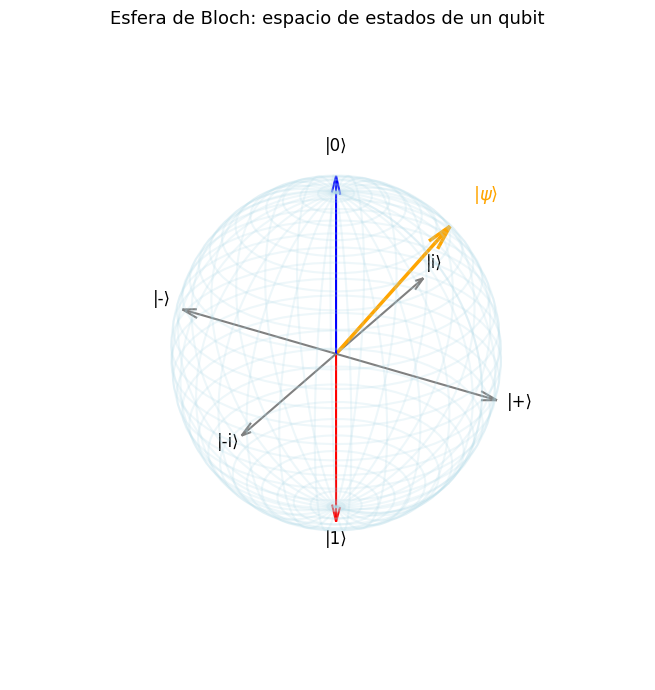

Cada punto en la superficie de la esfera representa un estado puro de un qubit.
|0⟩ está en el polo norte, |1⟩ en el polo sur.
El ecuador contiene estados de superposición igual (|α|² = |β|² = 1/2).


In [1]:
# Visualización: el espacio de estados de un qubit (esfera de Bloch)
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')

# Dibujar la esfera
u = np.linspace(0, 2*np.pi, 60)
v = np.linspace(0, np.pi, 60)
x = np.outer(np.cos(u), np.sin(v))
y = np.outer(np.sin(u), np.sin(v))
z = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_wireframe(x, y, z, color='lightblue', alpha=0.2)

# Ejes
for vec, label, color in [([1,0,0],'|+⟩','gray'), ([-1,0,0],'|-⟩','gray'),
                           ([0,1,0],'|i⟩','gray'), ([0,-1,0],'|-i⟩','gray'),
                           ([0,0,1],'|0⟩','blue'), ([0,0,-1],'|1⟩','red')]:
    ax.quiver(0,0,0, *vec, length=1.1, arrow_length_ratio=0.1, color=color, linewidth=1.5)
    ax.text(vec[0]*1.25, vec[1]*1.25, vec[2]*1.25, label, fontsize=12, ha='center')

# Estado ejemplo: θ=π/4, φ=π/4
theta, phi = np.pi/4, np.pi/4
sx = np.sin(theta)*np.cos(phi)
sy = np.sin(theta)*np.sin(phi)
sz = np.cos(theta)
ax.quiver(0,0,0, sx, sy, sz, length=1.0, arrow_length_ratio=0.15,
          color='orange', linewidth=2.5, label=r'$|\psi⟩$')
ax.text(sx*1.2, sy*1.2, sz*1.2, r'$|\psi⟩$', fontsize=13, color='orange')

ax.set_title('Esfera de Bloch: espacio de estados de un qubit', fontsize=13, pad=15)
ax.set_box_aspect([1,1,1])
ax.set_axis_off()
plt.tight_layout()
plt.show()
print("Cada punto en la superficie de la esfera representa un estado puro de un qubit.")
print("|0⟩ está en el polo norte, |1⟩ en el polo sur.")
print("El ecuador contiene estados de superposición igual (|α|² = |β|² = 1/2).")

---
<a id='sec2'></a>
## 2. Modelos de cómputo cuántico

Existen al menos tres modelos equivalentes para computación cuántica, cada uno con distintas ventajas para diseñar lenguajes:

### Modelo 1: Circuitos cuánticos

Basado en puertas cuánticas organizadas en un circuito acíclico dirigido (DAG).

**Componentes:**
- **Dispositivo de entrada**: inicializa qubits
- **Conjunto de puertas básicas**: se aplican secuencial y paralelamente
- **Dispositivo de medición**: al final del circuito

🔑 **Nota clave**: En este modelo puro, las mediciones ocurren solo al final. Se puede demostrar formalmente que siempre es posible "empujar" las mediciones al final del circuito. Sin embargo, esto es poco natural desde el punto de vista del programador.

### Modelo 2: Máquina de Turing Cuántica (QTM)

Análogo cuántico de la Máquina de Turing clásica. Muy útil para:
- Discutir **clases de complejidad cuántica** (BQP, QMA, etc.)
- Problemas teóricos de ciencias de la computación

❌ Poco útil para diseñar algoritmos o lenguajes de programación prácticos.

### Modelo 3: QRAM (Quantum Random Access Memory)

El más adecuado para programación práctica. ✅ **Este es el modelo que usamos en este curso.**

---

**Comparación de modelos:**

| Modelo | Utilidad teórica | Utilidad práctica | Naturalidad |
|--------|-----------------|-------------------|-------------|
| Circuitos cuánticos | Alta | Media | Media |
| Máquina de Turing Cuántica | Muy alta | Baja | Baja |
| **QRAM** | Media | **Alta** | **Alta** |

---
<a id='sec3'></a>
## 3. La Arquitectura QRAM

### 3.1 Descripción

El modelo **QRAM (Quantum Random Access Memory)** fue introducido por Knill (1996) y es considerado el primer paper conocido sobre programación cuántica.

La arquitectura consta de:

```
┌─────────────────────┐        instrucciones q-assembler        ┌─────────────────────┐
│  Computador Clásico  │  ─────────────────────────────────────▶  │  Procesador Cuántico │
│     (Master)         │                                          │      (Slave)         │
│                      │  ◀─────────────────────────────────────  │                      │
│  - Registro control  │         resultados de medición           │  - Registros qubits  │
│  - Lógica clásica    │                                          │  - Puertas unitarias │
└─────────────────────┘                                          └─────────────────────┘
                                          ↕
                              Quantum Hardware Interface (QHI)
```

### 3.2 Idea fundamental

El programador escribe **código clásico** en un lenguaje estándar (C, Python, etc.). Cuando necesita poder cuántico adicional, incorpora instrucciones de **ensamblador cuántico** (q-assembler).

Analogía: es similar a un desarrollador de juegos 3D que inserta instrucciones de GPU para operaciones matriciales intensivas.

### 3.3 La QHI (Quantum Hardware Interface)

La QHI traduce las instrucciones de ensamblador del master en acciones físicas sobre el dispositivo cuántico. El programador **no necesita conocer**:
- Cómo se almacenan físicamente los qubits
- Cómo se inicializan o manipulan a nivel de hardware
- Los detalles de la implementación física

Solo necesita conocer la **capacidad del dispositivo** (máximo de qubits disponibles).

---
<a id='sec4'></a>
## 4. Ensamblador Cuántico: Registros, Puertas y Medición

### 4.1 El registro cuántico (q-register)

**Definición 7.2.1** *(del libro)*: Un **registro cuántico** es una interfaz a una secuencia direccionable de qubits. Cada q-register tiene un identificador único.

Para nuestro ensamblador de juguete, asumimos registros de tamaño 8 (análogo a un byte → **qubyte**).

```
┌───┬───┬───┬───┬───┬───┬───┬───┐
│q₀ │q₁ │q₂ │q₃ │q₄ │q₅ │q₆ │q₇ │   ←  R1
└───┴───┴───┴───┴───┴───┴───┴───┘
  0   1   2   3   4   5   6   7    ←  índices
```

### 4.2 Instrucciones básicas del q-assembler

#### `INITIALIZE`
```
INITIALIZE R [INPUT]
```
Inicializa el registro `R`. Sin INPUT, todos los qubits van a $|0\rangle$.

```
INITIALIZE R1           // R1 = |00000000⟩
INITIALIZE R1 [00001111] // R1 = |00001111⟩
```

#### `SELECT`
```
SELECT S R OFFSET NUMQUBITS
```
Selecciona un subregistro de `NUMQUBITS` qubits a partir de la posición `OFFSET`.

```
INITIALIZE R1
SELECT S R1 2 3    // S = qubits 2, 3, 4 de R1
```

#### `APPLY`
```
APPLY U R
```
Aplica la transformación unitaria `U` al registro `R`.

#### `MEASURE`
```
MEASURE R RES
```
Mide el registro `R` y almacena el resultado (array de bits clásicos) en `RES`.

⚠️ **Caveat importante**: Al medir, se destruye el estado cuántico del registro.

### 4.3 Construcción de transformaciones unitarias

El ensamblador permite construir puertas complejas a partir de las básicas:

```
GATES = {H, Rθ, In, CNOT}
```

| Puerta | Notación | Matriz | Descripción |
|--------|----------|--------|-------------|
| Hadamard | $H$ | $\frac{1}{\sqrt{2}}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ | Crea superposición |
| Phase shift | $R_\theta$ | $\begin{pmatrix}1&0\\0&e^{i\theta}\end{pmatrix}$ | Rota la fase |
| Identidad | $I_n$ | $I_{n\times n}$ | No hace nada (padding) |
| CNOT | CNOT | $\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}$ | NOT controlado |

#### Operaciones sobre puertas:

```
U CONCAT U1 U2    // Composición: U = U2 · U1 (de derecha a izquierda)
U TENSOR U1 U2    // Producto tensorial: U = U1 ⊗ U2
U INVERSE U1      // Inversa: U = U1†
```

### 4.4 ¿Por qué no hay instrucción COPY?

> **Teorema de no-clonación**: Es imposible crear una copia perfecta de un estado cuántico arbitrario desconocido.

Esto implica que el ensamblador cuántico **no puede tener instrucción de copia** de registros, a diferencia de los ensambladores clásicos donde `MOV R1, R2` es ubicua.

### 4.5 Control: la ausencia de estructuras de control explícitas

En el modelo QRAM, las estructuras de control (`if/else`, `while`) se implementan en el **lenguaje huésped** (el código clásico del master). El ensamblador cuántico no las necesita directamente:

```python
# Ejemplo de control híbrido
INITIALIZE R 2
U TENSOR H I2
APPLY U R
MEASURE R RES

# Control clásico en el lenguaje huésped:
if RES == [10]:
    APPLY CNOT R
else:
    APPLY H R
```

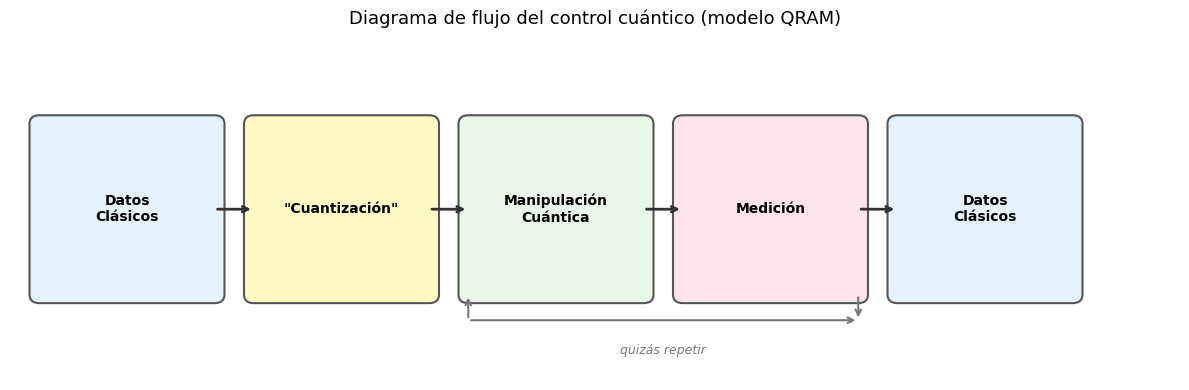

In [2]:
# Visualización: diagrama de flujo del control cuántico QRAM
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 4))
ax.set_xlim(0, 12)
ax.set_ylim(0, 4)
ax.axis('off')

boxes = [
    (0.3, 1.0, 1.8, 2.0, '#E3F2FD', 'Datos\nClásicos'),
    (2.5, 1.0, 1.8, 2.0, '#FFF9C4', '"Cuantización"'),
    (4.7, 1.0, 1.8, 2.0, '#E8F5E9', 'Manipulación\nCuántica'),
    (6.9, 1.0, 1.8, 2.0, '#FCE4EC', 'Medición'),
    (9.1, 1.0, 1.8, 2.0, '#E3F2FD', 'Datos\nClásicos'),
]

for (x, y, w, h, color, label) in boxes:
    rect = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1",
                           facecolor=color, edgecolor='#555', linewidth=1.5)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, label, ha='center', va='center', fontsize=10, fontweight='bold')

# Flechas entre cajas
arrow_x = [2.1, 4.3, 6.5, 8.7]
for ax_x in arrow_x:
    ax.annotate('', xy=(ax_x + 0.4, 2.0), xytext=(ax_x, 2.0),
                arrowprops=dict(arrowstyle='->', color='#333', lw=2))

# Flecha de repetición (loop)
ax.annotate('', xy=(4.7, 0.7), xytext=(8.7, 0.7),
            arrowprops=dict(arrowstyle='<-', color='#777', lw=1.5,
                           connectionstyle='arc3,rad=0'))
ax.text(6.7, 0.35, 'quizás repetir', ha='center', va='center',
        fontsize=9, color='#777', style='italic')
ax.annotate('', xy=(4.7, 1.0), xytext=(4.7, 0.7),
            arrowprops=dict(arrowstyle='->', color='#777', lw=1.5))
ax.annotate('', xy=(8.7, 0.7), xytext=(8.7, 1.0),
            arrowprops=dict(arrowstyle='->', color='#777', lw=1.5))

ax.set_title('Diagrama de flujo del control cuántico (modelo QRAM)', fontsize=13, pad=10)
plt.tight_layout()
plt.show()

### 4.6 Ejemplo completo: superposición uniforme de 2 qubits

Tracemos el siguiente programa en q-assembler:

```
INITIALIZE R 2
U TENSOR H H
APPLY U R
MEASURE R RES
```

**Análisis paso a paso:**

**Paso 1**: `INITIALIZE R 2` → $|R\rangle = |00\rangle$

**Paso 2**: `U = H ⊗ H` →  
$$U = H \otimes H = \frac{1}{2}\begin{pmatrix}1&1&1&1\\1&-1&1&-1\\1&1&-1&-1\\1&-1&-1&1\end{pmatrix}$$

**Paso 3**: `APPLY U R`:
$$U|00\rangle = \frac{1}{2}|00\rangle + \frac{1}{2}|01\rangle + \frac{1}{2}|10\rangle + \frac{1}{2}|11\rangle$$

**Paso 4**: `MEASURE R RES` → cada resultado tiene probabilidad $|\frac{1}{2}|^2 = \frac{1}{4} = 25\%$

Circuito equivalente al q-assembler:
     ┌───┐┌─┐   
q_0: ┤ H ├┤M├───
     ├───┤└╥┘┌─┐
q_1: ┤ H ├─╫─┤M├
     └───┘ ║ └╥┘
c: 2/══════╩══╩═
           0  1 


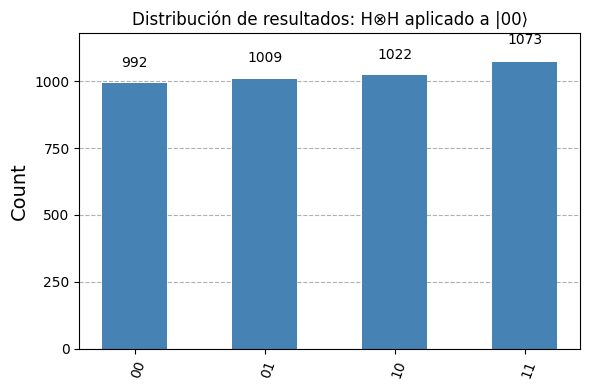


Resultados (4096 shots):
  |00⟩: 992 veces = 24.2%
  |01⟩: 1009 veces = 24.6%
  |10⟩: 1022 veces = 25.0%
  |11⟩: 1073 veces = 26.2%

→ Cada estado tiene aproximadamente 25% de probabilidad ✓


In [3]:
# Simulación del programa anterior con Qiskit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Construir el circuito equivalente al q-assembler
qc = QuantumCircuit(2, 2)
# INITIALIZE R 2  →  qubits ya en |00⟩ por defecto
# APPLY (H⊗H) R  →  Hadamard en cada qubit
qc.h(0)
qc.h(1)
# MEASURE R RES
qc.measure([0, 1], [0, 1])

print("Circuito equivalente al q-assembler:")
print(qc.draw(output='text'))

# Ejecutar simulación
sim = AerSimulator()
job = sim.run(qc, shots=4096)
counts = job.result().get_counts()

fig, ax = plt.subplots(figsize=(6, 4))
plot_histogram(counts, ax=ax, color='steelblue')
ax.set_title('Distribución de resultados: H⊗H aplicado a |00⟩', fontsize=12)
plt.tight_layout()
plt.show()

print("\nResultados (4096 shots):")
for state, count in sorted(counts.items()):
    print(f"  |{state}⟩: {count} veces = {count/4096*100:.1f}%")
print("\n→ Cada estado tiene aproximadamente 25% de probabilidad ✓")

---
<a id='sec5'></a>
## 5. Taxonomía de Lenguajes de Programación Cuántica

### 5.1 Clasificación por nivel de abstracción

```
                    NIVEL DE ABSTRACCIÓN
    
    Alto nivel  ┌──────────────────────────────────────┐
    (funcional) │  Quipper, QML, Q#, QFC (Selinger)    │
                ├──────────────────────────────────────┤
    Intermedio  │  Qiskit (Python), Cirq, PennyLane, Q │
    (SDK/SDK)   │  QCL (C-like), tket                  │
                ├──────────────────────────────────────┤
    Bajo nivel  │  OpenQASM, QASM 3, q-assembler        │
    (circuital) │  (lo visto en la sección anterior)   │
                └──────────────────────────────────────┘
    Máquina     │  Nivel físico / control de hardware  │
```

### 5.2 Paradigmas de programación aplicados a lo cuántico

La clasificación de lenguajes clásicos se traslada al dominio cuántico:

#### Paradigma Imperativo

- Programa = secuencia de comandos + estructuras de control
- Lenguajes: C++, Java, Python, PERL
- **Propuesta cuántica: QCL** (Bernhard Ömer)
  - Sintaxis tipo C
  - Tipo nuevo `QReg` para registros cuánticos
  - Puertas como operadores (análogo a funciones C)
  - Implementado en C++, descargable

```c
// Fragmento de QCL
qureg R[4];        // registro cuántico de 4 qubits
H(R[2]);           // Hadamard en el tercer qubit

operator myop(qureg q) {
    H(q);          // Hadamard
    Not(q);        // NOT
    CPhase(pi, q); // Phase shift controlado
}
```

- **Variante: Q** (Bettelli et al.)
  - Extensión de C++
  - Operadores como objetos de primera clase
  - `QRegisters` y `QOperators` como tipos

#### Paradigma Funcional

- Programa = especificación de función
- Lenguajes: LISP, ML, Haskell, Miranda
- Ventajas para lo cuántico:
  - Verificación de tipos en tiempo de compilación
  - Semántica denotacional y operacional bien establecida
  - Pruebas de corrección más naturales

**Propuestas cuánticas funcionales:**

| Lenguaje | Autores | Característica principal |
|----------|---------|-------------------------|
| **QFC** | Selinger (2004) | Datos cuánticos + control clásico, sintaxis de flowchart |
| **QML** | Grattage & Altenkirch (2005) | Afirma: datos Y control cuánticos |
| **Quipper** | Green et al. | Embebido en Haskell, muy expresivo |

#### Paradigma Lógico

- Programa = especificación de propiedades y relaciones en lógica de primer orden
- Lenguajes: Prolog
- **Propuestas cuánticas**: Ninguna establecida aún (al momento de redacción del libro)

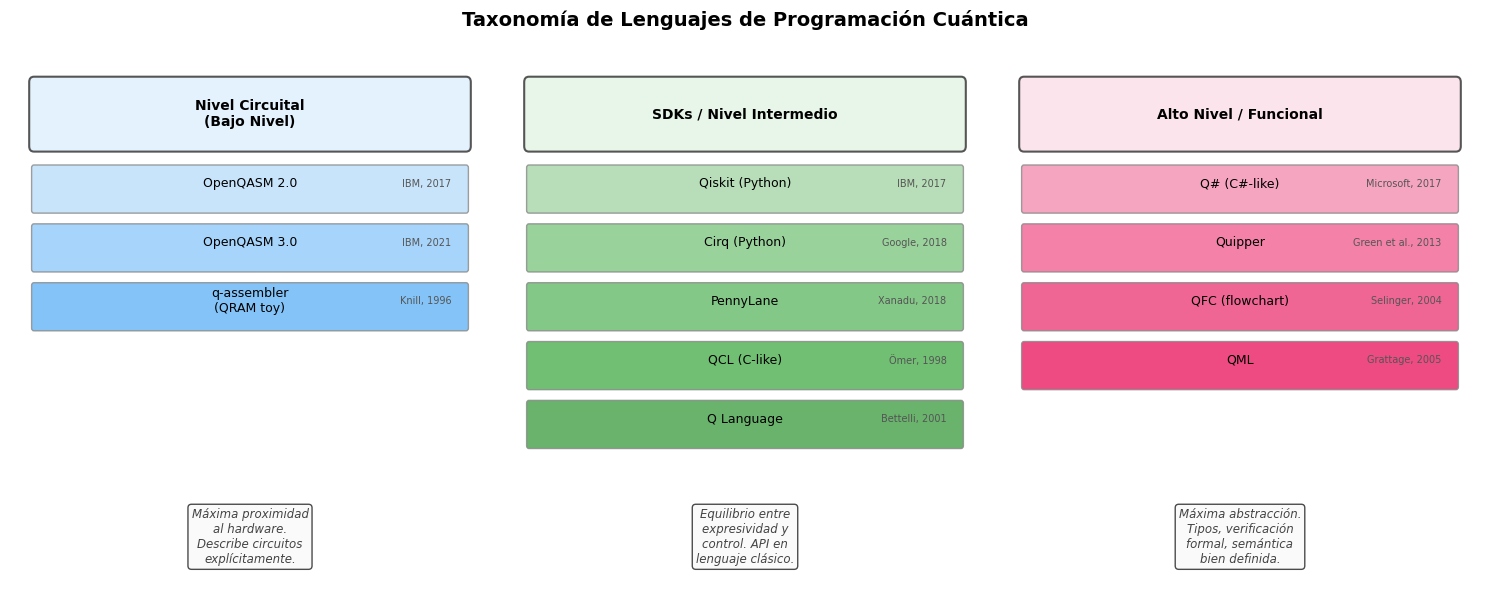

In [4]:
# Diagrama comparativo de la taxonomía
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

# Datos para cada columna
columnas = [
    {
        'titulo': 'Nivel Circuital\n(Bajo Nivel)',
        'color_header': '#E3F2FD',
        'items': [
            ('OpenQASM 2.0', '#BBDEFB', 'IBM, 2017'),
            ('OpenQASM 3.0', '#90CAF9', 'IBM, 2021'),
            ('q-assembler\n(QRAM toy)', '#64B5F6', 'Knill, 1996'),
        ],
        'desc': 'Máxima proximidad\nal hardware.\nDescribe circuitos\nexplícitamente.'
    },
    {
        'titulo': 'SDKs / Nivel Intermedio',
        'color_header': '#E8F5E9',
        'items': [
            ('Qiskit (Python)', '#A5D6A7', 'IBM, 2017'),
            ('Cirq (Python)', '#81C784', 'Google, 2018'),
            ('PennyLane', '#66BB6A', 'Xanadu, 2018'),
            ('QCL (C-like)', '#4CAF50', 'Ömer, 1998'),
            ('Q Language', '#43A047', 'Bettelli, 2001'),
        ],
        'desc': 'Equilibrio entre\nexpresividad y\ncontrol. API en\nlenguaje clásico.'
    },
    {
        'titulo': 'Alto Nivel / Funcional',
        'color_header': '#FCE4EC',
        'items': [
            ('Q# (C#-like)', '#F48FB1', 'Microsoft, 2017'),
            ('Quipper', '#F06292', 'Green et al., 2013'),
            ('QFC (flowchart)', '#EC407A', 'Selinger, 2004'),
            ('QML', '#E91E63', 'Grattage, 2005'),
        ],
        'desc': 'Máxima abstracción.\nTipos, verificación\nformal, semántica\nbien definida.'
    },
]

for ax, col in zip(axes, columnas):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')
    
    # Header
    rect = mpatches.FancyBboxPatch((0.5, 8.5), 9, 1.2, boxstyle="round,pad=0.1",
                                   facecolor=col['color_header'], edgecolor='#555', lw=1.5)
    ax.add_patch(rect)
    ax.text(5, 9.1, col['titulo'], ha='center', va='center',
            fontsize=10, fontweight='bold')
    
    # Items
    y_pos = 7.8
    for (name, color, year) in col['items']:
        rect = mpatches.FancyBboxPatch((0.5, y_pos - 0.5), 9, 0.8,
                                       boxstyle="round,pad=0.05",
                                       facecolor=color, edgecolor='#888', lw=1, alpha=0.8)
        ax.add_patch(rect)
        ax.text(5, y_pos, name, ha='center', va='center', fontsize=9)
        ax.text(9.2, y_pos, year, ha='right', va='center', fontsize=7, color='#555')
        y_pos -= 1.1
    
    # Descripción
    ax.text(5, 1.2, col['desc'], ha='center', va='center',
            fontsize=8.5, style='italic', color='#444',
            bbox=dict(boxstyle='round', facecolor='#f9f9f9', alpha=0.7))

fig.suptitle('Taxonomía de Lenguajes de Programación Cuántica', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 5.3 QFC: Quantum Flow Charts (Selinger, 2004)

QFC propone la separación: **datos cuánticos + control clásico**.

El siguiente programa en QFC:

```
new qbit p, q := 0      // inicializa dos qubits en |0⟩
q *= H                  // aplica Hadamard al segundo qubit
measure q then          // mide q
    { p *= H }          // si resultado = 0: Hadamard en p
else
    { p *= NOT }        // si resultado = 1: NOT en p
```

Es equivalente al flowchart:

```
     [Allocate qubits p=0, q=0]
              |
         [q := H*q]
              |
         [measure q]
          /       \
       q=0         q=1
        |            |
  [p := H*p]   [p := NOT*p]
```

**Diferencia conceptual clave** con el paradigma puramente cuántico: en QFC, el **control** (la estructura `if/else`) es clásico —depende del resultado de una medición clásica. Los datos que se manipulan sí son cuánticos.

### 5.4 QML: Quantum ML (Grattage & Altenkirch, 2005)

QML va más allá y afirma que tanto los datos **como el control** son cuánticos. Introduce constructos como el `if cuántico` (`qif`), aunque con la restricción de que no pueden anidarse, lo cual limita la noción de control.

---
<a id='sec6'></a>
## 6. El Modelo Híbrido Clásico-Cuántico

### 6.1 ¿Por qué los LPQ no reemplazan a Python/C++?

Los lenguajes cuánticos **no reemplazan** a los clásicos. La razón es estructural:

1. **Entrada/Salida**: los datos del mundo real son clásicos (archivos, redes, pantallas)
2. **Control de flujo complejo**: bucles sobre datos clásicos, interfaz de usuario
3. **Librerías existentes**: ecosistema masivo de software clásico
4. **El hardware cuántico es un acelerador**: no una computadora completa

El paradigma es:

```
  Programa clásico (Python, C++, Java)
         │
         │  cuando se necesita aceleración cuántica:
         ▼
  ┌──────────────────────┐
  │  Subrutina cuántica   │  ← circuito cuántico o q-assembler
  └──────────────────────┘
         │
         │  resultado clásico (bits)
         ▼
  Continúa el programa clásico
```

### 6.2 Algoritmos cuánticos relevantes y sus tipos de datos

Incluso desde los algoritmos del Capítulo 6 del libro, la necesidad de tipos de datos de alto nivel emerge:

| Algoritmo | Tipo de dato lógico | Representación en qubits |
|-----------|--------------------|--------------------------|
| **Shor** (factorización) | Enteros | Secuencias de qubits (binario) |
| **Grover** (búsqueda) | Índices, booleanos | Secuencias de qubits |
| **Deutsch-Jozsa** | Funciones f:{0,1}ⁿ→{0,1} | Oracle $U_f$ |
| **QFT** | Amplitudes en frecuencia | Coeficientes de la superposición |

### 6.3 Funciones clásicas como transformaciones unitarias

Un desafío fundamental: ¿cómo representar una función clásica $f: \{0,1\}^n \rightarrow \{0,1\}^n$ como transformación unitaria?

**Si $f$ es invertible**: simplemente extendemos por linealidad.

**Si $f$ NO es invertible** (caso general): usamos el truco de Bennett:

$$U_f: |x\rangle|y\rangle \rightarrow |x\rangle|f(x) \oplus y\rangle$$

En particular, con $y = 0$:

$$U_f: |x\rangle|0\rangle \rightarrow |x\rangle|f(x)\rangle$$

Esto convierte cualquier función irreversible en una reversible, a costo de duplicar el tamaño del registro.

### 6.4 El Quantum Scratch Pad (Bennett)

Para componer funciones sin acumular qubits auxiliares:

$$|x, 0, 0\rangle \xrightarrow{U_f} |x, f(x), 0\rangle \xrightarrow{U_g} |x, f(x), g(f(x))\rangle \xrightarrow{U_f^{-1}} |x, 0, g(f(x))\rangle$$

Al deshacer $U_f$ en el tercer paso, liberamos los qubits intermedios para reutilización.

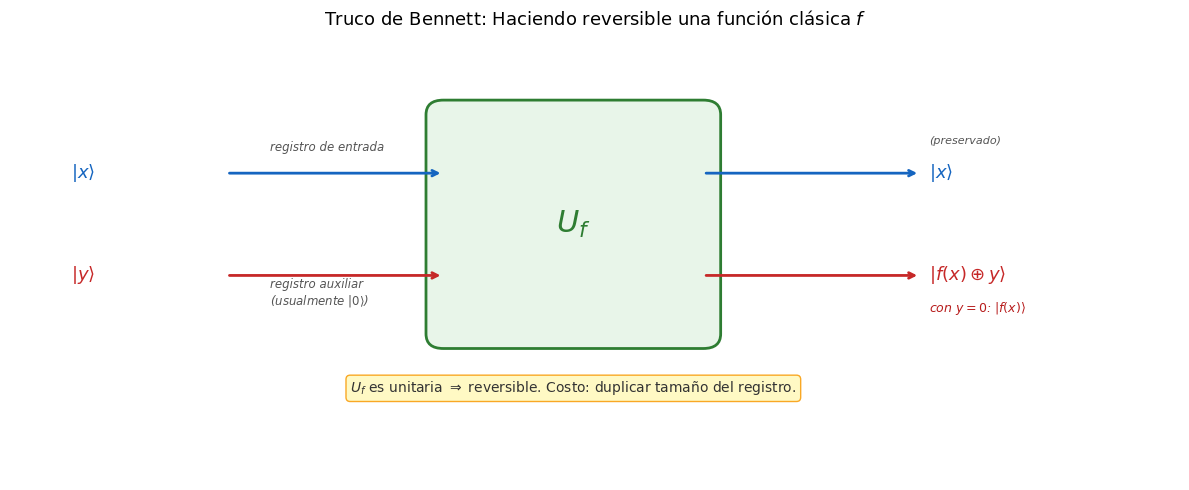

In [5]:
# Visualización: cómo funciona el truco Uf para funciones no invertibles
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_xlim(-0.5, 13)
ax.set_ylim(-1, 5)
ax.axis('off')
ax.set_title('Truco de Bennett: Haciendo reversible una función clásica $f$', fontsize=13, pad=12)

# Caja Uf
box = mpatches.FancyBboxPatch((4.5, 1.0), 3, 3, boxstyle="round,pad=0.2",
                              facecolor='#E8F5E9', edgecolor='#2E7D32', lw=2)
ax.add_patch(box)
ax.text(6, 2.5, '$U_f$', ha='center', va='center', fontsize=22, color='#2E7D32', fontweight='bold')

# Entradas
ax.annotate('', xy=(4.5, 3.2), xytext=(2, 3.2),
            arrowprops=dict(arrowstyle='->', color='#1565C0', lw=2))
ax.text(0.2, 3.2, r'$|x\rangle$', va='center', fontsize=13, color='#1565C0')
ax.text(2.5, 3.5, 'registro de entrada', fontsize=8.5, color='#555', style='italic')

ax.annotate('', xy=(4.5, 1.8), xytext=(2, 1.8),
            arrowprops=dict(arrowstyle='->', color='#C62828', lw=2))
ax.text(0.2, 1.8, r'$|y\rangle$', va='center', fontsize=13, color='#C62828')
ax.text(2.5, 1.4, 'registro auxiliar\n(usualmente $|0\\rangle$)', fontsize=8.5, color='#555', style='italic')

# Salidas
ax.annotate('', xy=(10, 3.2), xytext=(7.5, 3.2),
            arrowprops=dict(arrowstyle='->', color='#1565C0', lw=2))
ax.text(10.1, 3.2, r'$|x\rangle$', va='center', fontsize=13, color='#1565C0')
ax.text(10.1, 3.6, '(preservado)', fontsize=8, color='#555', style='italic')

ax.annotate('', xy=(10, 1.8), xytext=(7.5, 1.8),
            arrowprops=dict(arrowstyle='->', color='#C62828', lw=2))
ax.text(10.1, 1.8, r'$|f(x) \oplus y\rangle$', va='center', fontsize=13, color='#C62828')
ax.text(10.1, 1.3, r'con $y=0$: $|f(x)\rangle$', fontsize=9, color='#B71C1C', style='italic')

# Nota de reversibilidad
ax.text(6, 0.2, r'$U_f$ es unitaria $\Rightarrow$ reversible. Costo: duplicar tamaño del registro.',
        ha='center', fontsize=10, color='#333',
        bbox=dict(boxstyle='round', facecolor='#FFF9C4', edgecolor='#F9A825'))

plt.tight_layout()
plt.show()

---
<a id='sec7'></a>
## 7. Emuladores Cuánticos

### 7.1 ¿Qué es un emulador cuántico?

En ausencia de computadoras cuánticas de propósito general, podemos **emular** comportamiento cuántico en hardware clásico.

**Limitación fundamental**: La simulación crece **exponencialmente** en el número de qubits.

- Un registro de $N$ qubits requiere $2^N$ números complejos
- Las transformaciones unitarias son matrices $2^N \times 2^N$
- Con $N = 50$: $2^{50} \approx 10^{15}$ números complejos → varios petabytes

### 7.2 Qiskit Aer como emulador

Qiskit Aer es el simulador estándar de referencia. Implementa:

| Simulador | Descripción | Límite práctico |
|-----------|-------------|----------------|
| `statevector_simulator` | Simula el vector de estado exacto | ~30 qubits |
| `qasm_simulator` | Muestrea de la distribución | ~50 qubits |
| `aer_simulator` | Multimodo, GPU-accelerable | Varía |

### 7.3 Qué se necesita para construir un emulador desde cero

Según el libro (Sección 7.4):

1. **Representar qubits**: pares de números complejos normalizados
2. **Representar registros**: arrays de $2^N$ números complejos
3. **Representar puertas**: matrices $2^N \times 2^N$ unitarias
4. **Aplicar puertas**: multiplicación matricial
5. **Medición**: sampling según $|\alpha_i|^2$

In [6]:
# Mini-emulador cuántico desde cero (sin Qiskit)
# Implementa exactamente lo descrito en la Sección 7.4 del libro

import numpy as np

class MiniQuantumEmulator:
    """
    Emulador cuántico mínimo basado en la descripción de la Sección 7.4.
    Implementa qubits como vectores de estado y puertas como matrices unitarias.
    """
    
    # Puertas básicas (GATES del libro)
    H  = np.array([[1,1],[1,-1]], dtype=complex) / np.sqrt(2)  # Hadamard
    I2 = np.eye(2, dtype=complex)                               # Identidad 2x2
    X  = np.array([[0,1],[1,0]], dtype=complex)                 # NOT / Pauli-X
    
    CNOT = np.array([[1,0,0,0],
                     [0,1,0,0],
                     [0,0,0,1],
                     [0,0,1,0]], dtype=complex)                 # Controlled-NOT
    
    @staticmethod
    def initialize(n_qubits, input_bits=None):
        """INITIALIZE R [INPUT] — inicializa un registro de n qubits."""
        state = np.zeros(2**n_qubits, dtype=complex)
        if input_bits is None:
            state[0] = 1.0  # |000...0⟩
        else:
            idx = int(''.join(str(b) for b in input_bits), 2)
            state[idx] = 1.0
        return state
    
    @staticmethod
    def apply(state, gate):
        """APPLY U R — aplica la puerta unitaria al estado."""
        return gate @ state
    
    @staticmethod
    def tensor(U1, U2):
        """U TENSOR U1 U2 — producto de Kronecker."""
        return np.kron(U1, U2)
    
    @staticmethod
    def concat(U1, U2):
        """U CONCAT U1 U2 — composición (U2 primero, luego U1)."""
        return U1 @ U2
    
    @staticmethod
    def measure(state, n_qubits, shots=1):
        """MEASURE R RES — mide el registro, retorna resultados clásicos."""
        probs = np.abs(state)**2
        outcomes = np.random.choice(2**n_qubits, p=probs, size=shots)
        results = [format(o, f'0{n_qubits}b') for o in outcomes]
        return results

# Reproducir el Ejemplo 7.2.4 del libro
em = MiniQuantumEmulator()

print("=" * 55)
print("  Ejemplo 7.2.4 del libro — Emulador desde cero")
print("=" * 55)

# INITIALIZE R 2
state = em.initialize(2)
print(f"\nEstado inicial |00⟩:")
for i, amp in enumerate(state):
    if abs(amp) > 1e-10:
        print(f"  |{format(i,'02b')}⟩: {amp:.4f}")

# U TENSOR H H
U = em.tensor(em.H, em.H)
print(f"\nMatriz U = H⊗H (4×4):")
print(np.round(U, 4))

# APPLY U R
state = em.apply(state, U)
print(f"\nEstado tras H⊗H aplicado a |00⟩:")
labels = ['|00⟩', '|01⟩', '|10⟩', '|11⟩']
for label, amp in zip(labels, state):
    print(f"  {label}: {amp:.4f}  (prob = {abs(amp)**2:.4f})")

# MEASURE R RES
results = em.measure(state, 2, shots=1000)
from collections import Counter
counts = Counter(results)
print(f"\nResultados tras 1000 mediciones:")
for state_str, count in sorted(counts.items()):
    bar = '█' * (count // 20)
    print(f"  |{state_str}⟩: {count:4d}  {bar}")
print(f"\n¿Probabilidad de |11⟩? {counts['11']/1000:.3f} ≈ 0.25 ✓")

  Ejemplo 7.2.4 del libro — Emulador desde cero

Estado inicial |00⟩:
  |00⟩: 1.0000+0.0000j

Matriz U = H⊗H (4×4):
[[ 0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j]
 [ 0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j]
 [ 0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j]
 [ 0.5+0.j -0.5+0.j -0.5+0.j  0.5-0.j]]

Estado tras H⊗H aplicado a |00⟩:
  |00⟩: 0.5000+0.0000j  (prob = 0.2500)
  |01⟩: 0.5000+0.0000j  (prob = 0.2500)
  |10⟩: 0.5000+0.0000j  (prob = 0.2500)
  |11⟩: 0.5000+0.0000j  (prob = 0.2500)

Resultados tras 1000 mediciones:
  |00⟩:  232  ███████████
  |01⟩:  266  █████████████
  |10⟩:  250  ████████████
  |11⟩:  252  ████████████

¿Probabilidad de |11⟩? 0.252 ≈ 0.25 ✓


---
<a id='sec8'></a>
## 8. Referencias y Lectura Adicional

### Referencias del capítulo

- **Knill, E. (1996)**. Conventions for quantum pseudocode. *LAUR-96-2724*, Los Alamos National Laboratory. *(Primera referencia conocida sobre programación cuántica — introdujo QRAM)*

- **Ömer, B.** QCL — A Programming Language for Quantum Computers. Tesis, TU Viena. http://tph.tuwien.ac.at/~oemer/qcl.html

- **Bettelli, S., Calarco, T., & Serafini, L. (2003)**. Toward an architecture for quantum programming. *EPJD*. *(Lenguaje Q)*

- **Selinger, P. (2004a)**. A survey of quantum programming languages. *MSCS*. *(Survey comprensivo)*

- **Selinger, P. (2004b)**. Towards a quantum programming language. *MSCS*. *(QFC)*

- **Grattage, J. & Altenkirch, T. (2005)**. A functional quantum programming language. *LICS*. *(QML)*

- **Gay, S.J. (2005)**. Quantum programming languages: Survey and bibliography. *MSCS*.

- **Nagarajan, R., Papanikolaou, N., & Williams, D. (2005)**. Simulating and compiling code for the Sequential Quantum Random Access Machine.

- **Bennett, C.H. (1973, 1989)**. Logical reversibility of computation; *Time/Space trade-offs for reversible computation*.

### Documentación actual

- **IBM Quantum / Qiskit**: https://docs.quantum.ibm.com
- **Google Cirq**: https://quantumai.google/cirq
- **Microsoft Q#**: https://docs.microsoft.com/en-us/azure/quantum/
- **PennyLane (Xanadu)**: https://pennylane.ai
- **Quantiki** (wiki de computación cuántica): https://www.quantiki.org

---

## Resumen del Notebook 1

| Concepto | Descripción |
|----------|-------------|
| Qubit | Par de complejos $(\alpha, \beta)$ con $|\alpha|^2 + |\beta|^2 = 1$ |
| Puerta cuántica | Matriz unitaria $U$ (reversible) |
| Medición | Proyección destructiva, resultado clásico |
| QRAM | Master clásico + slave cuántico vía QHI |
| No-clonación | No existe instrucción COPY en q-assembler |
| Paradigma híbrido | LPQ no reemplazan Python; son un acelerador |
| QCL | C-like, imperativo, implementado |
| QFC | Flowchart, datos cuánticos + control clásico |
| QML | Funcional, afirma control cuántico también |
| Emulador | Simulación exponencialmente costosa en RAM clásica |

---

**Continúa en el Notebook 2 →** donde implementarás estos conceptos en Qiskit.